# Coincidence solution — notebook

*Fit the bridge on the decoder's behaviour, not on vector error.*

This notebook is the **reading** layer over `results/*.json`: it reproduces every table and figure in
`REPORT.md` from the saved artefacts, in seconds. The expensive steps (encoding, training, generation)
are separate scripts — see the last section.

Session: 2026-11-26 · vi→en · `t5-small-vietnamese` → `t5-small` + `trans-t5-small-vi-en` LoRA · 263 200-parameter map · $0 API.

In [1]:
import json
from pathlib import Path
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

R = Path("results")
J = lambda n: json.loads((R / n).read_text(encoding="utf-8"))

def table(rows, cols, fmt=None):
    fmt = fmt or {}
    head = "| " + " | ".join(cols) + " |"
    sep = "|" + "|".join("---" for _ in cols) + "|"
    body = ["| " + " | ".join(fmt.get(c, lambda v: str(v))(r[c]) for c in cols) + " |" for r in rows]
    print("\n".join([head, sep] + body))

print("artefacts:", sorted(p.name for p in R.glob("*.json")))

artefacts: ['basis_analysis.json', 'behaviour_maps.json', 'bootstrap.json', 'calibration.json', 'coincidence.json', 'comet.json', 'diag_maxnew.json', 'diag_recolor.json', 'maxnew48.json', 'replicate.json']


## 1. Calibration — is this code the same instrument E9 used?

`CE` is the precision-insensitive quantity, so it must match `GEN_VARIANTS.md` exactly; BLEU drifts
because E9 decoded in bf16 with `max_new=48`.

In [2]:
cal = J("calibration.json")
rows = [{"channel": k, **v} for k, v in cal["channels"].items()]
table(rows, ["channel", "bleu", "chrf", "ce", "degen", "norm"],
      {"bleu": lambda v: f"{v:.2f}", "chrf": lambda v: f"{v:.2f}",
       "ce": lambda v: f"{v:.3f}", "degen": lambda v: f"{v:.3f}", "norm": lambda v: f"{v:.1f}"})
print("\nE9 published:", cal["expected_e9"])

| channel | bleu | chrf | ce | degen | norm |
|---|---|---|---|---|---|
| ridge | 2.50 | 19.77 | 3.228 | 0.155 | 7.6 |
| native | 3.75 | 14.72 | 3.413 | 0.342 | 28.8 |
| ref | 74.22 | 84.70 | 0.302 | 0.011 | 17.6 |

E9 published: {'ridge': {'bleu': 2.73, 'chrf': 19.73, 'ce': 3.228}, 'native': {'bleu': 4.2, 'chrf': 14.82, 'ce': 3.413}}


The third row is what makes the night possible: **the decoder reading the English reference gets
74 BLEU**. A perfect memory exists, so "the decoder is the bottleneck" and "the map is the bottleneck"
can finally be separated.

## 2. Every arm, at both decoding settings

`max_new=64` is this package's setting; `max_new=48` is E9/E7/E8's, which is why the second table
exists. `ridge_sub` is the published objective refitted on the *same* 20 k pairs the CE arms see —
that is the control that makes this about the objective rather than the corpus.

In [3]:
b = J("behaviour_maps.json")["arms"]
m = J("maxnew48.json")["arms"]
rows = []
for k, v in b.items():
    rows.append({"arm": k, "bleu64": v["bleu"], "chrf64": v["chrf"], "ce": v["ce"],
                 "degen": v["degen"], "norm": v["norm"], "zdist": v["zdist_med"],
                 "val_ce": v["val_ce"], "bleu48": m.get(k, {}).get("bleu")})
table(rows, ["arm", "bleu64", "bleu48", "chrf64", "ce", "degen", "norm", "zdist", "val_ce"],
      {"bleu64": lambda v: f"{v:.2f}", "bleu48": lambda v: "—" if v is None else f"{v:.2f}",
       "chrf64": lambda v: f"{v:.2f}", "ce": lambda v: f"{v:.3f}",
       "degen": lambda v: f"{v:.3f}", "norm": lambda v: f"{v:.1f}",
       "zdist": lambda v: f"{v:.1f}", "val_ce": lambda v: f"{v:.3f}"})

| arm | bleu64 | bleu48 | chrf64 | ce | degen | norm | zdist | val_ce |
|---|---|---|---|---|---|---|---|---|
| ridge_full | 2.50 | 2.71 | 19.77 | 3.228 | 0.155 | 7.6 | 6.2 | 3.303 |
| ridge_sub | 2.47 | 2.67 | 19.68 | 3.232 | 0.167 | 7.6 | 6.2 | 3.307 |
| ce_ridge | 5.33 | 5.72 | 25.00 | 2.857 | 0.118 | 9.3 | 10.6 | 2.929 |
| ce_scratch | 2.25 | 2.43 | 17.28 | 3.314 | 0.265 | 24.4 | 33.7 | 3.364 |
| ridge_recolor10 | 3.08 | 3.43 | 20.70 | 3.262 | 0.144 | 8.8 | 8.6 | 3.344 |
| ridge_recolor30 | 1.68 | — | 13.40 | 4.318 | 0.386 | 14.0 | 17.0 | 4.462 |
| ridge_recolor50 | 0.79 | — | 6.83 | 6.067 | 0.629 | 20.6 | 26.5 | 6.249 |
| ridge_scale122 | 2.89 | 3.21 | 20.88 | 3.248 | 0.190 | 9.3 | 7.9 | 3.325 |
| ce_ridge_e6 | 7.04 | 7.59 | 27.24 | 2.761 | 0.090 | 11.3 | 14.3 | 2.825 |
| distill | 7.25 | 7.77 | 27.57 | 2.741 | 0.104 | 11.9 | 15.4 | 2.809 |
| ce_ridge_e16 | 7.90 | 8.46 | 29.36 | 2.738 | 0.067 | 13.8 | 18.8 | 2.797 |


In [4]:
# paired bootstrap vs the published map (500 resamples over sentences)
boot = J("bootstrap.json")
for k, v in boot.items():
    print(f"{k:18s} dBLEU {v['bleu']['delta']:+.2f} "
          f"[{v['bleu']['ci'][0]:+.2f}, {v['bleu']['ci'][1]:+.2f}]  p>0 {v['bleu']['p_gt0']:.2f}")

ce_ridge           dBLEU +2.83 [+2.29, +3.47]  p>0 1.00
ce_ridge_e6        dBLEU +4.55 [+3.78, +5.26]  p>0 1.00
ce_scratch         dBLEU -0.26 [-0.77, +0.33]  p>0 0.20
ridge_recolor10    dBLEU +0.59 [-0.08, +1.42]  p>0 0.93
ridge_scale122     dBLEU +0.39 [-0.27, +1.19]  p>0 0.81
ridge_sub          dBLEU -0.03 [-0.22, +0.17]  p>0 0.41
distill            dBLEU +4.75 [+3.92, +5.57]  p>0 1.00
ce_ridge_e16       dBLEU +5.40 [+4.50, +6.27]  p>0 1.00


Reading: the least-squares bridge and its 20 k-pair refit are indistinguishable (**the data was
never the limit**); pure isotropic rescaling to the CE arm's norm buys +0.39; E9's recolour buys
+0.59; the CE objective buys **+2.83 (2 epochs)** and **+4.55 (6 epochs)**. CE from an identity
initialisation *does not beat* ridge (2.25, CI includes 0) and lands in a worse basin — so MSE is a
good initialiser and a bad objective.

### 2b. An independent learned metric ranks the arms the same way

BLEU can reward fluent-but-unfaithful output (the Oct-31 pilot's failure mode), so every arm was
scored with `Unbabel/wmt22-comet-da` on 400 sentences.

In [5]:
comet = J("comet.json")["arms"]
rows = [{"arm": k, "bleu": b[k]["bleu"], "comet": v["comet"]} for k, v in comet.items() if k in b]
rows.sort(key=lambda r: r["bleu"])
table(rows, ["arm", "bleu", "comet"], {"bleu": lambda v: f"{v:.2f}", "comet": lambda v: f"{v:.4f}"})
print("\nmonotone in BLEU across all arms:", all(
    a["comet"] < b_["comet"] for a, b_ in zip(rows, rows[1:])))

| arm | bleu | comet |
|---|---|---|
| ce_scratch | 2.25 | 0.4363 |
| ridge_sub | 2.47 | 0.4751 |
| ridge_full | 2.50 | 0.4797 |
| ridge_scale122 | 2.89 | 0.4898 |
| ridge_recolor10 | 3.08 | 0.4966 |
| ce_ridge | 5.33 | 0.5331 |
| ce_ridge_e6 | 7.04 | 0.5641 |
| distill | 7.25 | 0.5678 |
| ce_ridge_e16 | 7.90 | 0.5830 |

monotone in BLEU across all arms: True


## 3. The decoder's level set — how far can the memory move before the answer changes?

Displacement `ε` is a fraction of the memory's own Frobenius norm. Left: oracle = target encoder
reading the English reference (74 BLEU). Right: oracle = the decoder's own `native` channel, where
positions are comparable with the map's memory.

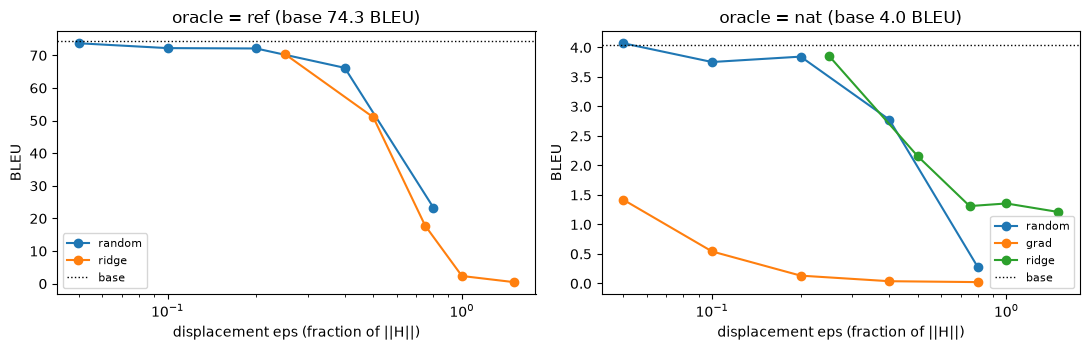


[ref] base BLEU 74.34  CE 0.290  ||H|| 17.4
  random e0.05: id 0.78 bleu 73.7 ce 0.29  e0.1: id 0.64 bleu 72.2 ce 0.30  e0.2: id 0.47 bleu 72.1 ce 0.32  e0.4: id 0.21 bleu 66.2 ce 0.41  e0.8: id 0.03 bleu 23.3 ce 1.02
  ridge  e0.25: id 0.38 bleu 70.4 ce 0.33  e0.5: id 0.11 bleu 51.0 ce 0.62  e0.75: id 0.02 bleu 17.8 ce 1.74  e1.0: id 0.00 bleu 2.4 ce 3.32  e1.5: id 0.00 bleu 0.5 ce 4.92

[nat] base BLEU 4.04  CE 3.396  ||H|| 28.7
  random e0.05: id 0.41 bleu 4.1 ce 3.40  e0.1: id 0.19 bleu 3.8 ce 3.42  e0.2: id 0.07 bleu 3.8 ce 3.50  e0.4: id 0.01 bleu 2.8 ce 3.81  e0.8: id 0.00 bleu 0.3 ce 4.94
  grad   e0.05: id 0.00 bleu 1.4 ce 7.16  e0.1: id 0.00 bleu 0.5 ce 9.10  e0.2: id 0.00 bleu 0.1 ce 11.33  e0.4: id 0.00 bleu 0.0 ce 13.23  e0.8: id 0.00 bleu 0.0 ce 14.54
  ridge  e0.25: id 0.09 bleu 3.9 ce 3.36  e0.5: id 0.01 bleu 2.2 ce 3.43  e0.75: id 0.00 bleu 1.3 ce 3.55  e1.0: id 0.00 bleu 1.4 ce 3.50  e1.5: id 0.00 bleu 1.2 ce 4.45


In [6]:
c = J("coincidence.json")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for a, (name, fams) in zip(ax, [("ref", ["random", "ridge"]), ("nat", ["random", "grad", "ridge"])]):
    o = c["oracles"][name]
    for fam in fams:
        rows = o["curves"][fam]
        a.plot([r["eps"] for r in rows], [r["bleu"] for r in rows], marker="o", label=fam)
    a.axhline(o["base"]["bleu"], ls=":", c="k", lw=1, label="base")
    a.set_title(f"oracle = {name} (base {o['base']['bleu']:.1f} BLEU)")
    a.set_xlabel("displacement eps (fraction of ||H||)")
    a.set_ylabel("BLEU")
    a.set_xscale("log")
    a.legend(fontsize=8)
plt.tight_layout()
plt.show()

for name in ("ref", "nat"):
    o = c["oracles"][name]
    print(f"\n[{name}] base BLEU {o['base']['bleu']:.2f}  CE {o['base']['ce']:.3f}  ||H|| {o['base']['norm']:.1f}")
    for fam, rows in o["curves"].items():
        print(f"  {fam:7s}" + "  ".join(
            f"e{r['eps']}: id {r['exact']:.2f} bleu {r['bleu']:.1f} ce {r['ce']:.2f}" for r in rows))

Two facts. **(a) The level set is thin**: a 5 % random displacement already changes 22 % of outputs.
**(b) The decoder is wildly anisotropic**: at the *same* 5 % displacement on the `native` oracle, a
random direction is invisible (BLEU 4.07, CE 3.402) while the steepest direction halves BLEU (1.42)
and multiplies CE by 2.1 (7.164).

## 4. Where does the map's error live?

If the least-squares residual concentrated in directions the decoder ignores, the map would be
harmless. It does not: the residual is essentially isotropic with respect to the decoder's sensitive
subspace (chance = k/32768).

In [7]:
o = c["oracles"]["nat"]["sensitive_subspace"]
rows = [{"k": int(k), "energy_pct": v["energy_frac"] * 100, "chance_pct": v["chance"] * 100,
         "ratio": v["energy_frac"] / v["chance"]} for k, v in o["energy_in_topk"].items()]
table(rows, ["k", "energy_pct", "chance_pct", "ratio"],
      {"energy_pct": lambda v: f"{v:.3f}", "chance_pct": lambda v: f"{v:.3f}",
       "ratio": lambda v: f"{v:.2f}x"})
print(f"\ncos^2(gradient, ridge error) per sentence: {o['cos2_grad_ridge_per_sent']:.2e} "
      f"(chance {o['cos2_chance']:.2e})")

a = J("basis_analysis.json")
print("\ngradient spectrum (1000 sentences x 32768 dims):", a["spectrum"]["top5"],
      " energy in top-64 components:", a["spectrum"]["energy_top64"])
print("oracle:", a["oracle"])
table([{"arm": k, **v} for k, v in a["arms"].items()],
      ["arm", "bleu", "ce", "exact_vs_oracle", "chrf_vs_oracle", "zdist_med"],
      {"bleu": lambda v: f"{v:.2f}", "ce": lambda v: f"{v:.3f}",
       "exact_vs_oracle": lambda v: f"{v:.3f}", "chrf_vs_oracle": lambda v: f"{v:.1f}",
       "zdist_med": lambda v: f"{v:.1f}"})

| k | energy_pct | chance_pct | ratio |
|---|---|---|---|
| 1 | 0.002 | 0.003 | 0.77x |
| 8 | 0.030 | 0.024 | 1.24x |
| 64 | 0.277 | 0.195 | 1.42x |
| 256 | 1.043 | 0.781 | 1.33x |

cos^2(gradient, ridge error) per sentence: 2.63e-05 (chance 3.05e-05)

gradient spectrum (1000 sentences x 32768 dims): [9.453, 8.787, 8.534, 8.293, 8.118]  energy in top-64 components: 0.4345
oracle: {'bleu': 74.217, 'ce': 0.3017}
| arm | bleu | ce | exact_vs_oracle | chrf_vs_oracle | zdist_med |
|---|---|---|---|---|---|
| ridge_full | 2.50 | 3.228 | 0.000 | 19.1 | 6.2 |
| ridge_sub | 2.47 | 3.232 | 0.000 | 19.1 | 6.2 |
| ridge_recolor10 | 3.08 | 3.262 | 0.000 | 19.9 | 8.6 |
| ridge_scale122 | 2.89 | 3.248 | 0.000 | 20.2 | 7.9 |
| ce_ridge | 5.33 | 2.857 | 0.000 | 24.2 | 10.6 |
| ce_ridge_e6 | 7.04 | 2.761 | 0.001 | 26.2 | 14.3 |
| ce_scratch | 2.25 | 3.314 | 0.000 | 16.4 | 33.7 |


`exact_vs_oracle ≈ 0` for every arm is the honest boundary: the CE objective improves the bridge
*within* the achievable set, but it does not reproduce the oracle's sentences. `chrf_vs_oracle` tracks
quality monotonically (19.1 → 24.2 → 26.2), which is a useful graded behavioural distance.

## 5. Qualitative check

In [8]:
H = Path("agent-work/hyps")
refs = json.loads((H / "refs.json").read_text(encoding="utf-8"))
ridge = json.loads((H / "ridge_full.json").read_text(encoding="utf-8"))
ce6 = json.loads((H / "ce_ridge_e6.json").read_text(encoding="utf-8"))
for i in (0, 3, 7, 11, 19):
    print(f"[{i}] REF   {refs[i]}")
    print(f"    RIDGE {ridge[i]}")
    print(f"    CE6   {ce6[i]}\n")

[0] REF   Find more of my witty (but clean) tweets @ ABCPress. â€ Now that you have your basic information, edit it so it has some personality.
    RIDGE " I've got a lot of information about you, " said the spokesman.
    CE6   " Find out more about the sluggishness of my self-inflicted sex, and the sex of the sex of the sex of the sex of the sex of the sex of the sex of the sex

[3] REF   In 1999, Metzen wrote a short story set in the StarCraft universe with fellow Blizzard Entertainment employee Sam Moore.
    RIDGE In 1894, the company was re-released by the late John S. Kennedy, a former entrepreneur who was a member of the American Academy of Music.
    CE6   In 1999, Vicki wrote a short story about the Battle of Rome with the former Fabiano assistant of Granada.

[7] REF   Click Install Helper
    RIDGE Click here to download the 'Select' button.
    CE6   Click on the link below to view the 'Download' button.

[11] REF   You are important to me.
    RIDGE But you are not alone

## 6. Regenerate (expensive)

```powershell
$py = "..\research-scale-100k\.venv\Scripts\python.exe"
& $py -m src.cache_states      # 150 s
& $py -m src.validate          # calibration, must print CE 3.228 / 3.413
& $py -m src.coincidence --n 300
& $py -m src.fit_behaviour --arms ridge_full,ridge_sub,ridge_recolor10,ridge_scale122,ce_ridge,ce_scratch
& $py -m src.fit_behaviour --arms ce_ridge_e6 --init-map ce_ridge --epochs 4
& $py -m src.analyse_basis
& $py -m src.eval_maxnew48
& $py -m src.eval_comet --n 400
& $py -m src.bootstrap_all
& $py -m src.cache_states --sets test2
& $py -m src.replicate
```

All idempotent: caches and `agent-work/maps/*.npz` are skipped when present (`--force` to rebuild).